# SmartCharge Urban — EV Charging Station Analytics
### Team: Strategic Signal | Course: Industry 4.0 | 2025–26

**Dataset:** Electric Vehicle Charging Patterns (1,320 sessions · 462 stations · 5 US cities)

---

### Parameter Guide

| Column (after aggregation) | Description |
|---|---|
| `station_id` | Unique charging station identifier |
| `city` | City where station is located |
| `sessions_per_day` | Total sessions recorded at the station |
| `energy_consumed_kwh` | Average kWh consumed per session |
| `utilisation_rate` | Avg session duration ÷ 24 hrs (0–1) |
| `installed_capacity_kw` | Max charging rate observed at station (kW) |
| `avg_charging_rate` | Mean charging rate across sessions (kW) |
| `cost_per_kwh` | Average cost per kWh (USD) — tariff proxy |
| `peak_hour_ratio` | Fraction of sessions in Morning/Afternoon/Evening |
| `battery_cap_mean` | Average battery capacity of vehicles served (kWh) |
| `distance_mean` | Avg distance driven since last charge (km) |
| `soc_end_mean` | Avg battery state-of-charge at session end (%) |
| `capex_usd` | Estimated capital cost (max_rate × $2,000/kW — NREL 2023) |
| `daily_co2_kg` | CO₂ per session (energy × 0.45 kg/kWh — US EPA average) |
| `dea_score` | BCC efficiency score (0–1); 1.0 = frontier station |
| `Composite_Score` | Weighted score: 40% DEA + 30% utilisation + 20% sessions + 10% cost |


## Step 0 · Install & Import

In [ ]:
!pip install pulp --quiet

import pandas as pd
import numpy as np
import random
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.optimize import linprog
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import pulp

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
random.seed(RANDOM_SEED)

print("All libraries loaded.")


All libraries loaded.


## Step 1 · Load Dataset

Single dataset — no joins required.  
Upload `ev_charging_patterns.csv` to Colab before running.


In [ ]:
import os
csv_path = 'ev_charging_patterns.csv'
if not os.path.exists(csv_path):
    for p in ['ev_charging_patterns.csv']:
        if os.path.exists(p):
            csv_path = p; break

df_raw = pd.read_csv(csv_path)
print('Shape         :', df_raw.shape)
print('Stations      :', df_raw['Charging Station ID'].nunique())
print('Cities        :', df_raw['Charging Station Location'].nunique())
print('Missing values:'); print(df_raw.isnull().sum()[df_raw.isnull().sum() > 0])
df_raw.head(3)


Shape         : (1320, 20)
Stations      : 462
Cities        : 5
Missing values:
Energy Consumed (kWh)                       66
Charging Rate (kW)                          66
Distance Driven (since last charge) (km)    66
dtype: int64


,User ID,Vehicle Model,Battery Capacity (kWh),Charging Station ID,Charging Station Location,Charging Start Time,Charging End Time,Energy Consumed (kWh),Charging Duration (hours),Charging Rate (kW),Charging Cost (USD),Time of Day,Day of Week,State of Charge (Start %),State of Charge (End %),Distance Driven (since last charge) (km),Temperature (°C),Vehicle Age (years),Charger Type,User Type
0,User_1,BMW i3,108.463007,Station_391,Houston,2024-01-01 00:00:00,2024-01-01 00:39:00,60.712346,0.591363,36.389181,13.087717,Evening,Tuesday,29.371576,86.119962,293.602111,27.947953,2.0,DC Fast Charger,Commuter
1,User_2,Hyundai Kona,100.000000,Station_428,San Francisco,2024-01-01 01:00:00,2024-01-01 03:01:00,12.339275,3.133652,30.677735,21.128448,Morning,Monday,10.115778,84.664344,112.112804,14.311026,3.0,Level 1,Casual Driver
2,User_3,Chevy Bolt,75.000000,Station_181,San Francisco,2024-01-01 02:00:00,2024-01-01 04:48:00,19.128876,2.452653,27.513593,35.667270,Morning,Thursday,6.854604,69.917615,71.799253,21.002002,2.0,Level 2,Commuter


## Step 2 · Preprocessing & Station-Level Aggregation

In [ ]:
# === Parse timestamps ===
df_raw["Charging Start Time"] = pd.to_datetime(df_raw["Charging Start Time"])
df_raw["Charging End Time"]   = pd.to_datetime(df_raw["Charging End Time"])

# === Derived session-level features ===
# Cost per kWh — tariff proxy
df_raw["cost_per_kwh"] = (
    df_raw["Charging Cost (USD)"] /
    df_raw["Energy Consumed (kWh)"].replace(0, np.nan)
)
df_raw["cost_per_kwh"].fillna(df_raw["cost_per_kwh"].median(), inplace=True)

# Peak hour flag: Morning / Afternoon / Evening = peak; Night = off-peak
df_raw["is_peak"] = df_raw["Time of Day"].isin(
    ["Morning", "Afternoon", "Evening"]).astype(int)

# === Aggregate to station level ===
station_df = (
    df_raw
    .groupby("Charging Station ID")
    .agg(
        sessions_per_day      = ("User ID",                                  "count"),
        energy_consumed_kwh   = ("Energy Consumed (kWh)",                    "mean"),
        duration_mean         = ("Charging Duration (hours)",                 "mean"),
        installed_capacity_kw = ("Charging Rate (kW)",                        "max"),
        avg_charging_rate     = ("Charging Rate (kW)",                        "mean"),
        cost_per_kwh          = ("cost_per_kwh",                              "mean"),
        peak_hour_ratio       = ("is_peak",                                   "mean"),
        battery_cap_mean      = ("Battery Capacity (kWh)",                    "mean"),
        distance_mean         = ("Distance Driven (since last charge) (km)",  "mean"),
        temp_mean             = ("Temperature (°C)",                          "mean"),
        soc_start_mean        = ("State of Charge (Start %)",                 "mean"),
        soc_end_mean          = ("State of Charge (End %)",                   "mean"),
        vehicle_age_mean      = ("Vehicle Age (years)",                       "mean"),
        city                  = ("Charging Station Location",                  "first"),
        charger_type          = ("Charger Type",          lambda x: x.mode()[0]),
        user_type             = ("User Type",             lambda x: x.mode()[0]),
    )
    .reset_index()
    .rename(columns={"Charging Station ID": "station_id"})
)

# Utilisation rate: avg session hours as fraction of a full day
station_df["utilisation_rate"] = (station_df["duration_mean"] / 24).clip(upper=1.0)

# Capital cost assumption: max_rate × $2,000/kW  (NREL 2023 benchmark)
station_df["capex_usd"] = station_df["installed_capacity_kw"] * 2000

# Carbon footprint: US EPA average grid factor 0.45 kg CO₂/kWh
station_df["emission_factor"] = 0.45
station_df["daily_co2_kg"]    = (station_df["energy_consumed_kwh"] * 0.45).round(2)

# Fill the small number of NaNs (from sessions with missing energy/distance)
station_df.fillna(station_df.median(numeric_only=True), inplace=True)

# Encode categoricals
le = LabelEncoder()
station_df["charger_type_enc"] = le.fit_transform(station_df["charger_type"])
station_df["city_enc"]         = le.fit_transform(station_df["city"])
station_df["user_type_enc"]    = le.fit_transform(station_df["user_type"])

print(f"Final dataset: {station_df.shape[0]} stations | {station_df['city'].nunique()} cities")
print("Missing values:", station_df.isnull().sum().sum())
station_df.describe().round(2)


/tmp/ipykernel_2771/36528389.py:11: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df_raw["cost_per_kwh"].fillna(df_raw["cost_per_kwh"].median(), inplace=True)


Final dataset: 462 stations | 5 cities
Missing values: 0


,sessions_per_day,energy_consumed_kwh,duration_mean,installed_capacity_kw,avg_charging_rate,cost_per_kwh,peak_hour_ratio,battery_cap_mean,distance_mean,temp_mean,soc_start_mean,soc_end_mean,vehicle_age_mean,utilisation_rate,capex_usd,emission_factor,daily_co2_kg,charger_type_enc,city_enc,user_type_enc
count,462.00,462.00,462.00,462.00,462.00,462.00,462.00,462.00,462.00,462.00,462.00,462.00,462.00,462.00,462.00,462.00,462.00,462.00,462.00,462.00
mean,2.86,42.10,2.28,35.75,26.26,2.39,0.75,74.51,154.48,15.24,49.56,75.13,3.61,0.09,71494.68,0.45,18.94,0.77,2.00,0.81
std,1.49,15.83,0.72,12.45,9.85,30.52,0.29,14.53,57.61,10.12,16.40,11.98,1.50,0.03,24903.29,0.00,7.12,0.79,1.37,0.78
min,1.00,0.05,0.42,3.86,3.86,0.04,0.00,24.57,11.74,-9.35,12.04,31.13,0.00,0.02,7711.57,0.45,0.02,0.00,0.00,0.00
25%,2.00,31.89,1.80,27.82,19.42,0.43,0.58,65.67,117.46,8.69,37.91,67.16,2.67,0.08,55635.06,0.45,14.34,0.00,1.00,0.00
50%,3.00,41.42,2.27,38.37,25.49,0.64,0.82,74.88,155.97,14.98,48.80,75.47,3.60,0.09,76738.51,0.45,18.64,1.00,2.00,1.00
75%,4.00,52.37,2.71,44.82,32.87,1.05,1.00,82.33,188.95,21.74,59.69,82.66,4.50,0.11,89645.92,0.45,23.56,1.00,3.00,1.00
max,9.00,84.54,5.26,97.34,56.97,654.76,1.00,147.40,398.36,50.09,112.49,177.71,7.00,0.22,194684.51,0.45,38.04,2.00,4.00,2.00


## Step 3 · Exploratory Data Analysis

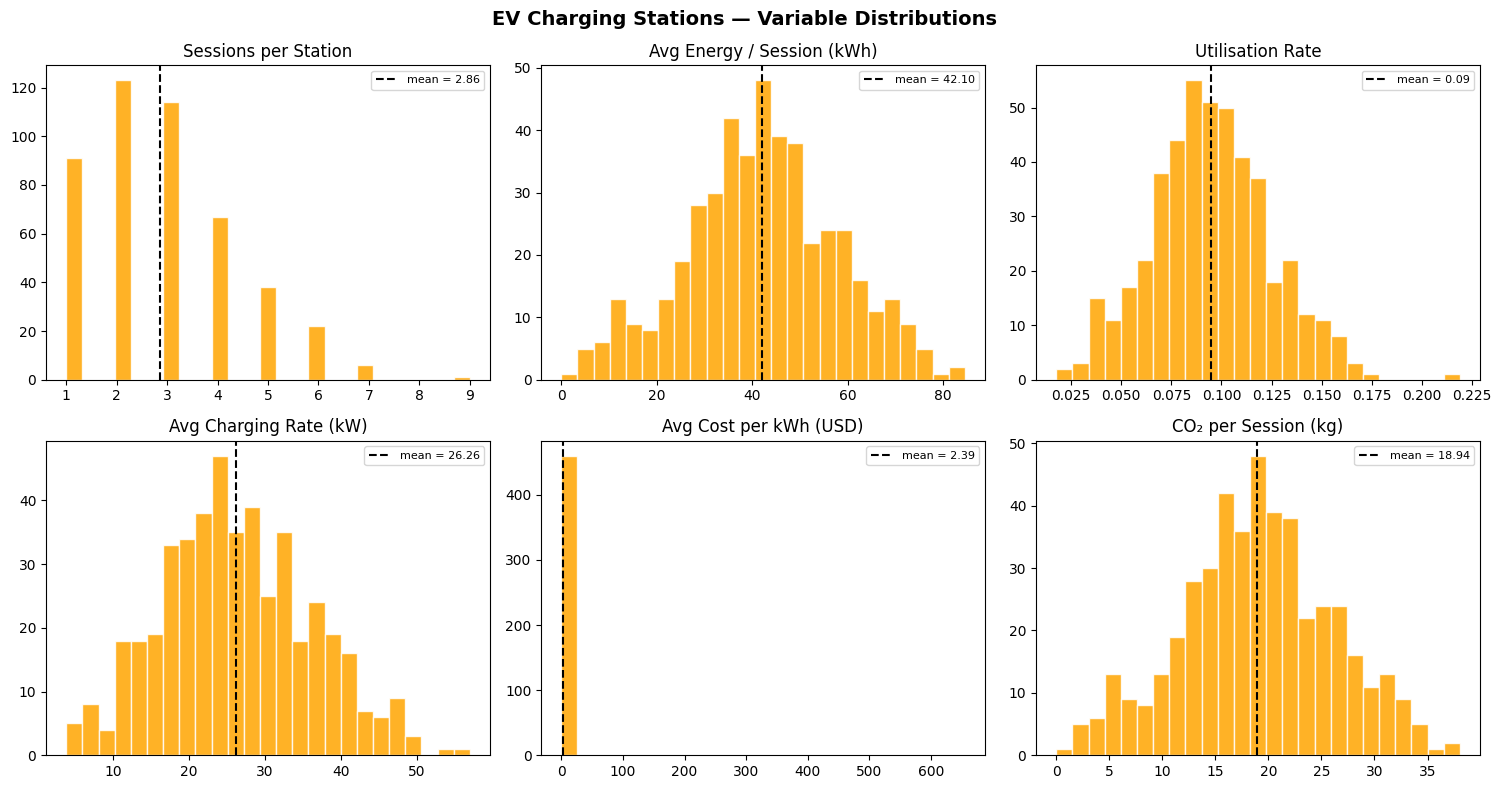

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

plot_vars = [
    ("sessions_per_day",    "Sessions per Station"),
    ("energy_consumed_kwh", "Avg Energy / Session (kWh)"),
    ("utilisation_rate",    "Utilisation Rate"),
    ("avg_charging_rate",   "Avg Charging Rate (kW)"),
    ("cost_per_kwh",        "Avg Cost per kWh (USD)"),
    ("daily_co2_kg",        "CO₂ per Session (kg)"),
]
for ax, (col, label) in zip(axes, plot_vars):
    ax.hist(station_df[col], bins=25, color="orange", edgecolor="white", alpha=0.85)
    ax.axvline(station_df[col].mean(), color="black", linestyle="--",
               label=f"mean = {station_df[col].mean():.2f}")
    ax.set_title(label); ax.legend(fontsize=8)

plt.suptitle("EV Charging Stations — Variable Distributions", fontsize=14, fontweight="bold")
plt.tight_layout(); plt.show()


City-level summary:
               stations  avg_sessions  avg_kwh  avg_util
city                                                    
Chicago              83         2.880   45.055     0.095
Houston              96         2.927   44.257     0.100
Los Angeles         111         2.955   40.887     0.091
New York             82         2.683   38.813     0.093
San Francisco        90         2.800   41.555     0.096


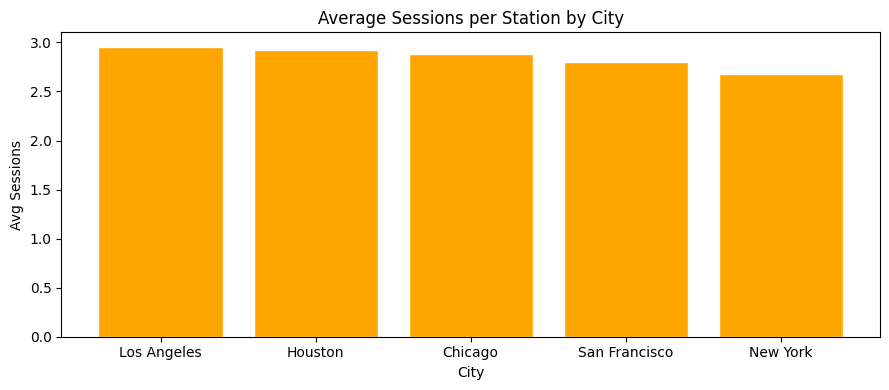

In [ ]:
# Sessions by city
city_stats = station_df.groupby("city").agg(
    stations     = ("station_id", "count"),
    avg_sessions = ("sessions_per_day", "mean"),
    avg_kwh      = ("energy_consumed_kwh", "mean"),
    avg_util     = ("utilisation_rate", "mean"),
).round(3)

print("City-level summary:")
print(city_stats)

plt.figure(figsize=(9, 4))
city_avg = station_df.groupby("city")["sessions_per_day"].mean().sort_values(ascending=False)
plt.bar(city_avg.index, city_avg.values, color="orange", edgecolor="white")
plt.title("Average Sessions per Station by City")
plt.ylabel("Avg Sessions"); plt.xlabel("City")
plt.tight_layout(); plt.show()


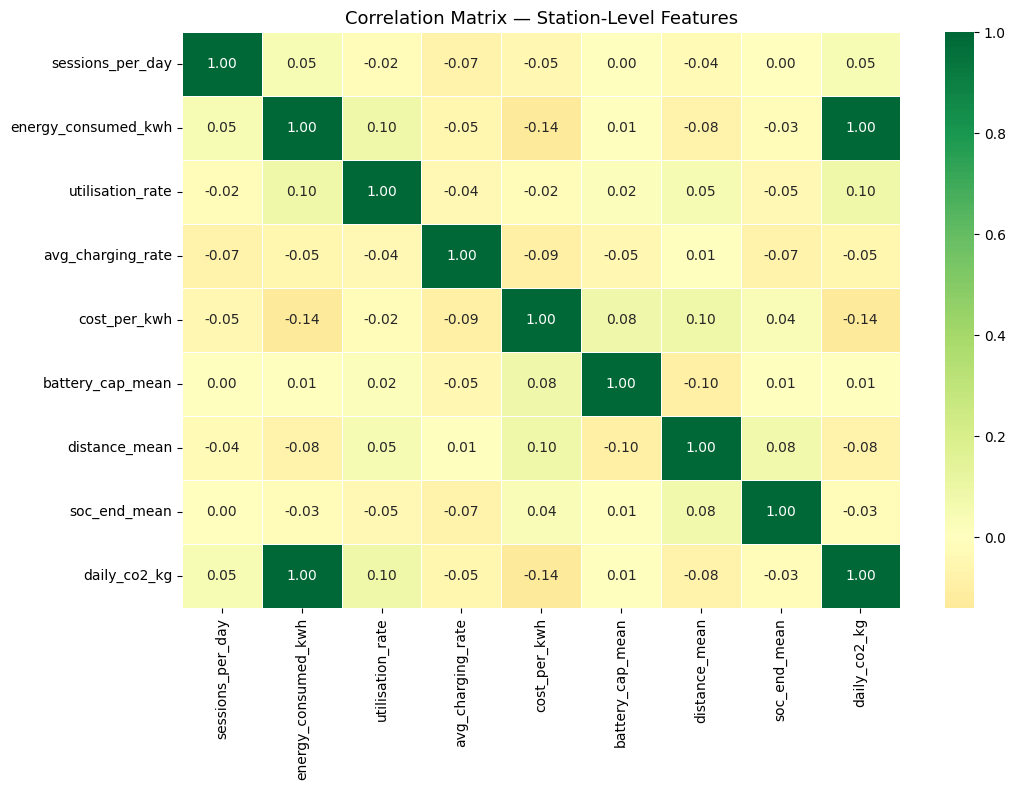

In [ ]:
# Correlation heatmap
num_cols = ["sessions_per_day","energy_consumed_kwh","utilisation_rate",
            "avg_charging_rate","cost_per_kwh","battery_cap_mean",
            "distance_mean","soc_end_mean","daily_co2_kg"]

plt.figure(figsize=(11, 8))
sns.heatmap(station_df[num_cols].corr(), annot=True, fmt=".2f",
            cmap="RdYlGn", center=0, linewidths=0.4)
plt.title("Correlation Matrix — Station-Level Features", fontsize=13)
plt.tight_layout(); plt.show()


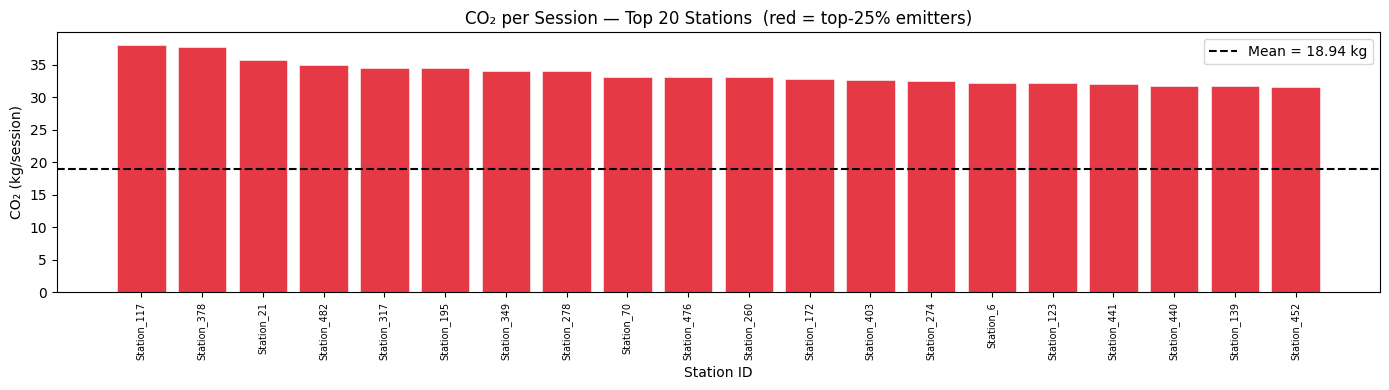

In [ ]:
# CO2 emissions — top 20 stations
df_co2 = station_df.sort_values("daily_co2_kg", ascending=False).head(20)
q75    = station_df["daily_co2_kg"].quantile(0.75)

plt.figure(figsize=(14, 4))
colors = ["#E63946" if v >= q75 else "orange" for v in df_co2["daily_co2_kg"]]
plt.bar(df_co2["station_id"], df_co2["daily_co2_kg"],
        color=colors, edgecolor="white", linewidth=0.4)
plt.axhline(station_df["daily_co2_kg"].mean(), color="black", linestyle="--",
            label=f"Mean = {station_df['daily_co2_kg'].mean():.2f} kg")
plt.title("CO₂ per Session — Top 20 Stations  (red = top-25% emitters)")
plt.xlabel("Station ID"); plt.ylabel("CO₂ (kg/session)")
plt.xticks(rotation=90, fontsize=7); plt.legend(); plt.tight_layout(); plt.show()


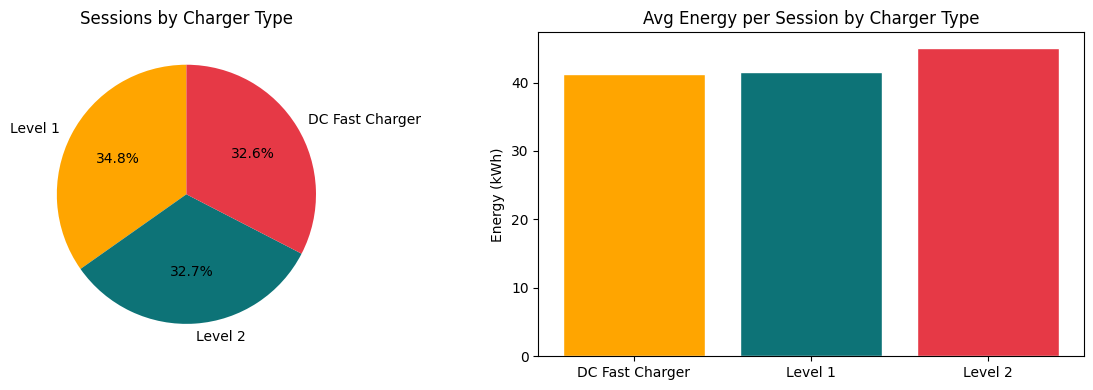

In [ ]:
# Charger type breakdown
ct_counts = df_raw["Charger Type"].value_counts()
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].pie(ct_counts, labels=ct_counts.index, autopct="%1.1f%%",
            colors=["orange","#0D7377","#E63946"], startangle=90)
axes[0].set_title("Sessions by Charger Type")

ct_kwh = df_raw.groupby("Charger Type")["Energy Consumed (kWh)"].mean()
axes[1].bar(ct_kwh.index, ct_kwh.values, color=["orange","#0D7377","#E63946"],
            edgecolor="white")
axes[1].set_title("Avg Energy per Session by Charger Type")
axes[1].set_ylabel("Energy (kWh)")

plt.tight_layout(); plt.show()


### Temporal Demand Heatmap


In [ ]:
day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
time_order = ["Morning", "Afternoon", "Evening", "Night"]

temporal_demand = pd.crosstab(df_raw["Day of Week"], df_raw["Time of Day"]).reindex(
    index=day_order, columns=time_order
)

plt.figure(figsize=(10, 5))
sns.heatmap(temporal_demand, annot=True, fmt="d", cmap="YlOrRd", linewidths=0.5, cbar_kws={"label": "Sessions"})
plt.title("Charging Demand Heatmap — Day of Week vs Time of Day", fontsize=13, fontweight="bold")
plt.xlabel("Time of Day")
plt.ylabel("Day of Week")
plt.tight_layout(); plt.show()

peak_day, peak_time = temporal_demand.stack().idxmax()
peak_count = int(temporal_demand.loc[peak_day, peak_time])
low_day, low_time = temporal_demand.stack().idxmin()
low_count = int(temporal_demand.loc[low_day, low_time])
weekend_share = temporal_demand.loc[["Saturday", "Sunday"]].to_numpy().sum() / temporal_demand.to_numpy().sum()

print(f"Total sessions captured in heatmap : {int(temporal_demand.to_numpy().sum())}")
print(f"Peak demand window                : {peak_day} {peak_time} ({peak_count} sessions)")
print(f"Quietest demand window            : {low_day} {low_time} ({low_count} sessions)")
print(f"Weekend session share             : {weekend_share:.1%}")


### User Type × Charger Type Segmentation


In [ ]:
segmentation_df = (
    df_raw.groupby(["User Type", "Charger Type"])
    .agg(
        session_count=("User ID", "count"),
        avg_energy_kwh=("Energy Consumed (kWh)", "mean"),
        avg_duration_hours=("Charging Duration (hours)", "mean"),
        avg_cost_usd=("Charging Cost (USD)", "mean"),
    )
    .round(2)
    .reset_index()
)

energy_matrix = segmentation_df.pivot(index="User Type", columns="Charger Type", values="avg_energy_kwh")

plt.figure(figsize=(9, 4.5))
sns.heatmap(energy_matrix, annot=True, fmt=".2f", cmap="YlOrBr", linewidths=0.5, cbar_kws={"label": "Avg Energy (kWh)"})
plt.title("User Type × Charger Type — Average Energy per Session", fontsize=13, fontweight="bold")
plt.xlabel("Charger Type")
plt.ylabel("User Type")
plt.tight_layout(); plt.show()

print(f"Total segmented sessions : {int(segmentation_df['session_count'].sum())}")
print(segmentation_df.to_string(index=False))

top_energy_combo = segmentation_df.loc[segmentation_df["avg_energy_kwh"].idxmax()]
top_cost_combo = segmentation_df.loc[segmentation_df["avg_cost_usd"].idxmax()]
print(f"\nHighest-energy segment : {top_energy_combo['User Type']} × {top_energy_combo['Charger Type']} ({top_energy_combo['avg_energy_kwh']:.2f} kWh)")
print(f"Highest-cost segment   : {top_cost_combo['User Type']} × {top_cost_combo['Charger Type']} (${top_cost_combo['avg_cost_usd']:.2f})")


## Step 4 · DEA — Efficiency Benchmarking

**BCC Output-Oriented DEA** (Variable Returns to Scale) implemented from scratch via `scipy`.

| Role | Variable | Rationale |
|---|---|---|
| Input | `capex_usd` | Capital invested in the station |
| Input | `avg_charging_rate` | Power drawn per session |
| Input | `vehicle_age_mean` | Older vehicles are harder/slower to charge |
| Output | `sessions_per_day` | Volume of service delivered |
| Output | `energy_consumed_kwh` | Energy throughput per session |
| Output | `soc_end_mean` | Quality of charge delivered (% battery filled) |

Score = 1.0 → frontier station. Stations in the **bottom quartile (score < 0.70)** are flagged for intervention.


In [ ]:
def run_bcc_dea(inputs, outputs):
    # BCC Output-Oriented DEA via scipy linprog
    # For each DMU o: max phi  s.t. Y*lambda >= phi*y_o,  X*lambda <= x_o,
    #                               sum(lambda)=1 (BCC),  lambda >= 0
    X = np.array(inputs,  dtype=float)
    Y = np.array(outputs, dtype=float)
    n, m = X.shape; _, s = Y.shape
    scores = []

    for o in range(n):
        x_o, y_o = X[o], Y[o]
        c = np.zeros(1 + n); c[0] = -1.0   # minimise -phi

        A_ub, b_ub = [], []
        for r in range(s):                   # -Y*lambda + phi*y_o <= 0
            row = np.zeros(1 + n)
            row[0] = y_o[r]; row[1:] = -Y[:, r]
            A_ub.append(row); b_ub.append(0.0)
        for i in range(m):                   # X*lambda <= x_o
            row = np.zeros(1 + n)
            row[1:] = X[:, i]
            A_ub.append(row); b_ub.append(x_o[i])

        A_eq = np.zeros((1, 1 + n)); A_eq[0, 1:] = 1.0   # sum(lambda) = 1
        bounds = [(1.0, None)] + [(0.0, None)] * n

        res = linprog(c, A_ub=np.array(A_ub), b_ub=np.array(b_ub),
                      A_eq=A_eq, b_eq=np.array([1.0]),
                      bounds=bounds, method="highs")
        scores.append(round(1.0 / res.x[0], 4) if res.success and res.x[0] > 0 else np.nan)

    return scores

INPUT_COLS  = ["capex_usd", "avg_charging_rate", "vehicle_age_mean"]
OUTPUT_COLS = ["sessions_per_day", "energy_consumed_kwh", "soc_end_mean"]

print("Running BCC DEA on 462 stations...")
station_df["dea_score"] = run_bcc_dea(
    station_df[INPUT_COLS].values,
    station_df[OUTPUT_COLS].values
)

DEA_THRESHOLD = station_df["dea_score"].quantile(0.25)   # bottom quartile

print(f"\n{'='*50}")
print(f"  DEA Results Summary")
print(f"{'='*50}")
print(f"  Frontier stations  (score = 1.00) : {(station_df['dea_score']==1.0).sum()}")
print(f"  Below threshold    (score < {DEA_THRESHOLD:.2f}) : {(station_df['dea_score']<DEA_THRESHOLD).sum()}")
print(f"  Mean score                        : {station_df['dea_score'].mean():.4f}")
print(f"  Min / Max                         : {station_df['dea_score'].min():.4f} / {station_df['dea_score'].max():.4f}")
print(f"{'='*50}")


Running BCC DEA on 462 stations...

  DEA Results Summary
  Frontier stations  (score = 1.00) : 33
  Below threshold    (score < 0.69) : 116
  Mean score                        : 0.7894
  Min / Max                         : 0.3775 / 1.0000


/tmp/ipykernel_2771/3709244524.py:17: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = axes[1].boxplot(city_data, labels=city_order, patch_artist=True,


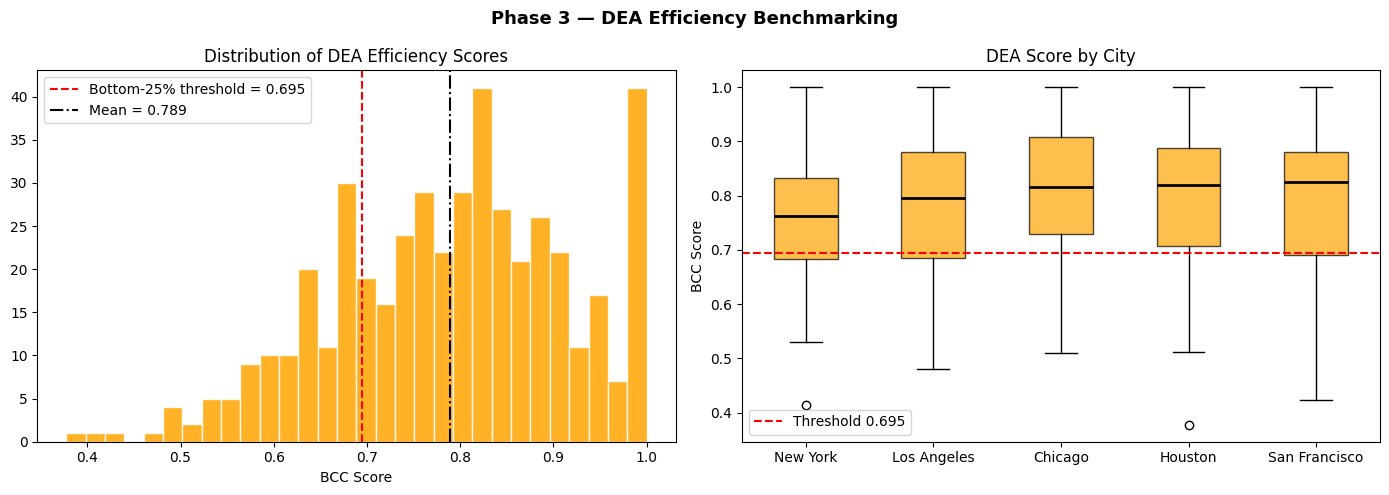

In [ ]:
# DEA score distribution
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogram
axes[0].hist(station_df["dea_score"], bins=30, color="orange",
             edgecolor="white", alpha=0.85)
axes[0].axvline(DEA_THRESHOLD, color="red", linestyle="--",
                label=f"Bottom-25% threshold = {DEA_THRESHOLD:.3f}")
axes[0].axvline(station_df["dea_score"].mean(), color="black", linestyle="-.",
                label=f"Mean = {station_df['dea_score'].mean():.3f}")
axes[0].set_title("Distribution of DEA Efficiency Scores")
axes[0].set_xlabel("BCC Score"); axes[0].legend()

# Box plot by city
city_order = station_df.groupby("city")["dea_score"].median().sort_values().index
city_data  = [station_df[station_df["city"]==c]["dea_score"].values for c in city_order]
bp = axes[1].boxplot(city_data, labels=city_order, patch_artist=True,
                     medianprops=dict(color="black", lw=2))
for patch in bp["boxes"]:
    patch.set_facecolor("orange"); patch.set_alpha(0.7)
axes[1].axhline(DEA_THRESHOLD, color="red", linestyle="--",
                label=f"Threshold {DEA_THRESHOLD:.3f}")
axes[1].set_title("DEA Score by City"); axes[1].legend()
axes[1].set_ylabel("BCC Score")

plt.suptitle("Phase 3 — DEA Efficiency Benchmarking", fontsize=13, fontweight="bold")
plt.tight_layout(); plt.show()


/tmp/ipykernel_2771/3668768770.py:16: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp2 = axes[1].boxplot(ct_data, labels=ct_order, patch_artist=True,


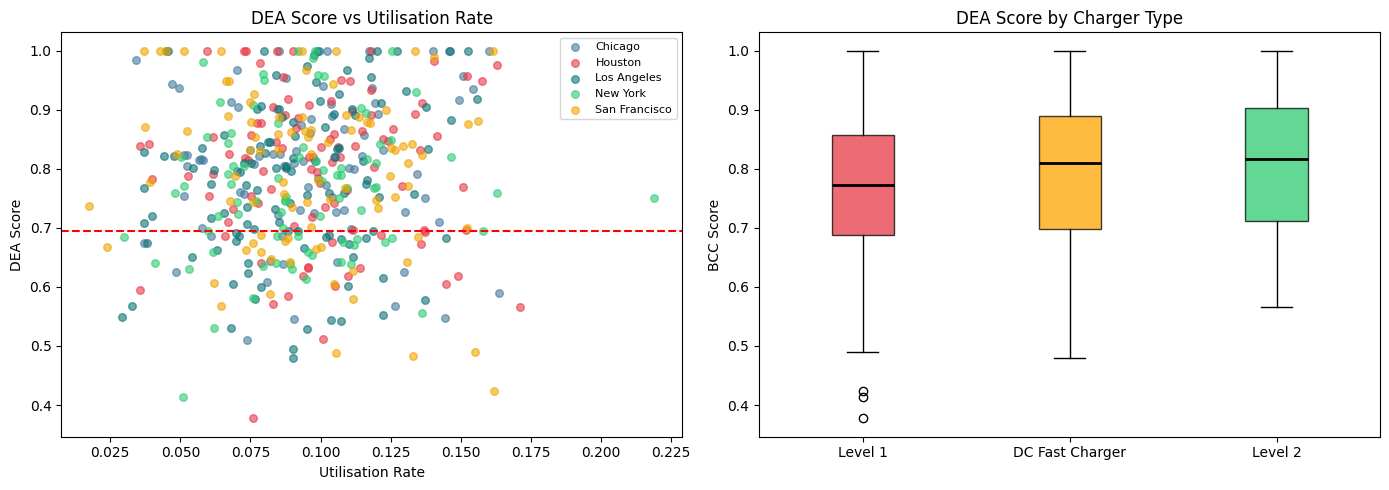


─── Bottom-10 Stations (Lowest DEA Scores) ───
 station_id          city    charger_type  dea_score  sessions_per_day  utilisation_rate  potential_gain
 Station_24       Houston         Level 1     0.3775                 1          0.075909             1.6
Station_425      New York         Level 1     0.4142                 1          0.050918             1.4
Station_466 San Francisco         Level 1     0.4236                 1          0.162052             1.4
Station_464   Los Angeles DC Fast Charger     0.4800                 2          0.090116             2.2
Station_314 San Francisco DC Fast Charger     0.4829                 2          0.133072             2.1
Station_299 San Francisco DC Fast Charger     0.4880                 2          0.105593             2.1
Station_331 San Francisco         Level 1     0.4891                 1          0.155169             1.0
Station_175   Los Angeles DC Fast Charger     0.4952                 1          0.090188             1.0
 Statio

In [ ]:
# DEA vs Utilisation scatter
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

city_colors = {"Los Angeles": "#0D7377", "San Francisco": "#F0A500",
               "Houston": "#E63946", "New York": "#2ECC71", "Chicago": "#457B9D"}
for city, grp in station_df.groupby("city"):
    axes[0].scatter(grp["utilisation_rate"], grp["dea_score"],
                    label=city, color=city_colors[city], alpha=0.6, s=30)
axes[0].axhline(DEA_THRESHOLD, color="red", linestyle="--", lw=1.5)
axes[0].set_xlabel("Utilisation Rate"); axes[0].set_ylabel("DEA Score")
axes[0].set_title("DEA Score vs Utilisation Rate"); axes[0].legend(fontsize=8)

# Charger type vs DEA
ct_order = station_df.groupby("charger_type")["dea_score"].median().sort_values().index
ct_data  = [station_df[station_df["charger_type"]==c]["dea_score"].values for c in ct_order]
bp2 = axes[1].boxplot(ct_data, labels=ct_order, patch_artist=True,
                      medianprops=dict(color="black", lw=2))
for patch, color in zip(bp2["boxes"], ["#E63946","orange","#2ECC71"]):
    patch.set_facecolor(color); patch.set_alpha(0.75)
axes[1].set_title("DEA Score by Charger Type"); axes[1].set_ylabel("BCC Score")

plt.tight_layout(); plt.show()

# Bottom-10 table
station_df["efficiency_label"] = station_df["dea_score"].apply(
    lambda s: "Frontier" if s==1.0 else ("Efficient" if s>=DEA_THRESHOLD else "Needs Improvement"))
station_df["potential_gain"] = (
    (1/station_df["dea_score"].clip(lower=0.01) - 1) * station_df["sessions_per_day"]
).round(1)

print("\n─── Bottom-10 Stations (Lowest DEA Scores) ───")
cols = ["station_id","city","charger_type","dea_score",
        "sessions_per_day","utilisation_rate","potential_gain"]
print(station_df.sort_values("dea_score").head(10)[cols].to_string(index=False))


## Step 5 · Multiple Linear Regression — Demand Forecasting

**Target:** `sessions_per_day` (total sessions recorded at each station)

**Predictors:** station capacity, charging rate, battery capacity of vehicles served,
distance driven by users, temperature, peak hour ratio, charger type, city.


In [ ]:
FEATURES = [
    "installed_capacity_kw",
    "avg_charging_rate",
    "battery_cap_mean",
    "distance_mean",
    "temp_mean",
    "peak_hour_ratio",
    "charger_type_enc",
    "city_enc",
]
TARGET = "sessions_per_day"

X = station_df[FEATURES].copy()
y = station_df[TARGET].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_SEED)

scaler_mlr = StandardScaler()
X_train_sc = scaler_mlr.fit_transform(X_train)
X_test_sc  = scaler_mlr.transform(X_test)

mlr = LinearRegression()
mlr.fit(X_train_sc, y_train)

y_pred_test = mlr.predict(X_test_sc)
r2_mlr  = r2_score(y_test, y_pred_test)
mae_mlr = mean_absolute_error(y_test, y_pred_test)

print(f"R² Score : {r2_mlr:.4f}")
print(f"MAE      : {mae_mlr:.4f}")


R² Score : 0.4581
MAE      : 0.9502


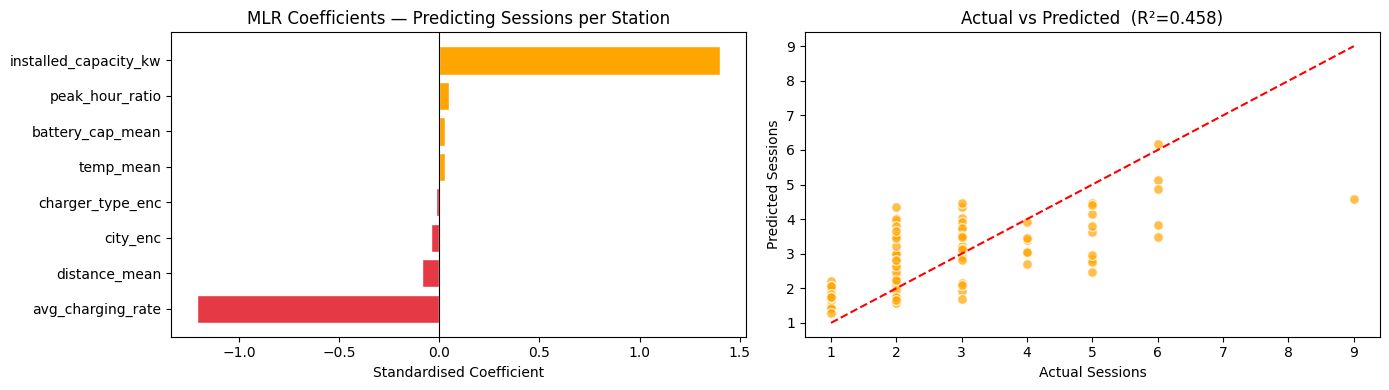

In [ ]:
# Coefficient plot
coef_df = pd.DataFrame({
    "Feature":     FEATURES,
    "Coefficient": mlr.coef_
}).sort_values("Coefficient")

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

colors = ["#E63946" if c < 0 else "orange" for c in coef_df["Coefficient"]]
axes[0].barh(coef_df["Feature"], coef_df["Coefficient"],
             color=colors, edgecolor="white")
axes[0].axvline(0, color="black", lw=0.8)
axes[0].set_title("MLR Coefficients — Predicting Sessions per Station")
axes[0].set_xlabel("Standardised Coefficient")

axes[1].scatter(y_test, y_pred_test, color="orange", alpha=0.7,
                edgecolors="white", s=50)
mn, mx = float(y_test.min()), float(y_test.max())
axes[1].plot([mn, mx], [mn, mx], "r--", lw=1.5)
axes[1].set_title(f"Actual vs Predicted  (R²={r2_mlr:.3f})")
axes[1].set_xlabel("Actual Sessions"); axes[1].set_ylabel("Predicted Sessions")

plt.tight_layout(); plt.show()


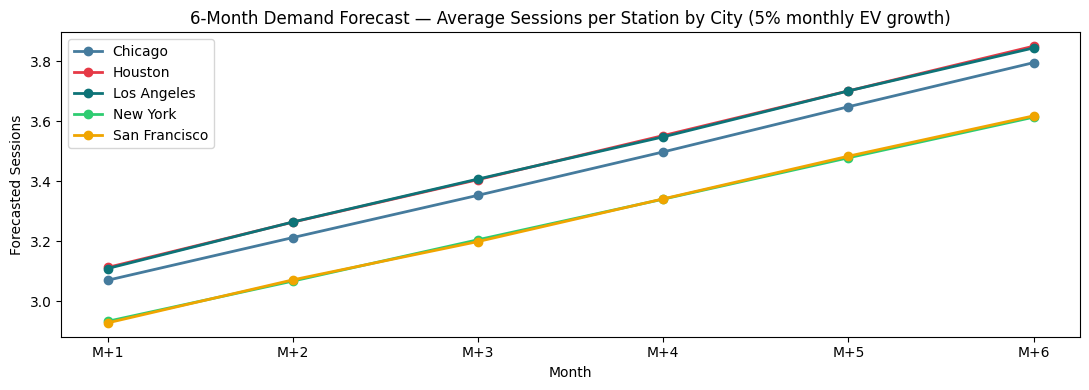

In [ ]:
# Forecast: predict sessions for all stations
X_all_sc = scaler_mlr.transform(X)
station_df["forecast_sessions"] = mlr.predict(X_all_sc).clip(min=1).round(1)

# Simulate 6-month growth (5% per month for growing EV fleet)
months = list(range(1, 7))
growth = [1 + 0.05 * m for m in months]

forecast_rows = []
for _, row in station_df.iterrows():
    for m, gf in zip(months, growth):
        forecast_rows.append({
            "station_id": row["station_id"],
            "city":       row["city"],
            "month":      m,
            "forecast_sessions": round(row["forecast_sessions"] * gf, 1)
        })
forecast_df = pd.DataFrame(forecast_rows)

# Plot by city
plt.figure(figsize=(11, 4))
city_forecast = forecast_df.groupby(["city","month"])["forecast_sessions"].mean().reset_index()
for city, grp in city_forecast.groupby("city"):
    plt.plot(grp["month"], grp["forecast_sessions"], marker="o",
             label=city, color=city_colors[city], lw=2)
plt.xticks(months, [f"M+{m}" for m in months])
plt.title("6-Month Demand Forecast — Average Sessions per Station by City (5% monthly EV growth)")
plt.ylabel("Forecasted Sessions"); plt.xlabel("Month"); plt.legend()
plt.tight_layout(); plt.show()


## Step 5A · Strategic Action Matrix

Use `forecast_sessions` and `dea_score` together to classify stations into upgrade, protect, review, and monitor zones.


In [ ]:
dea_median = station_df["dea_score"].median()
forecast_median = station_df["forecast_sessions"].median()

station_df["priority_quadrant"] = np.select(
    [
        (station_df["forecast_sessions"] >= forecast_median) & (station_df["dea_score"] < dea_median),
        (station_df["forecast_sessions"] >= forecast_median) & (station_df["dea_score"] >= dea_median),
        (station_df["forecast_sessions"] < forecast_median) & (station_df["dea_score"] < dea_median),
        (station_df["forecast_sessions"] < forecast_median) & (station_df["dea_score"] >= dea_median),
    ],
    [
        "High forecast / Low DEA",
        "High forecast / High DEA",
        "Low forecast / Low DEA",
        "Low forecast / High DEA",
    ],
    default="Unclassified",
)

quadrant_colors = {
    "High forecast / Low DEA": "#E63946",
    "High forecast / High DEA": "#2ECC71",
    "Low forecast / Low DEA": "#F4A261",
    "Low forecast / High DEA": "#457B9D",
}

plt.figure(figsize=(10, 6))
for quadrant, grp in station_df.groupby("priority_quadrant"):
    plt.scatter(
        grp["forecast_sessions"], grp["dea_score"],
        label=quadrant, color=quadrant_colors.get(quadrant, "gray"),
        alpha=0.75, s=55, edgecolors="white", linewidth=0.4
    )

plt.axvline(forecast_median, color="black", linestyle="--", lw=1.2, label=f"Median Forecast = {forecast_median:.1f}")
plt.axhline(dea_median, color="dimgray", linestyle="--", lw=1.2, label=f"Median DEA = {dea_median:.3f}")

upgrade_priority = station_df[station_df["priority_quadrant"] == "High forecast / Low DEA"].copy()
upgrade_priority = upgrade_priority.sort_values(["forecast_sessions", "dea_score"], ascending=[False, True]).head(8)
for _, row in upgrade_priority.iterrows():
    plt.annotate(row["station_id"], (row["forecast_sessions"], row["dea_score"]), xytext=(5, 5), textcoords="offset points", fontsize=8)

plt.title("Strategic Priority Matrix — Forecast Demand vs DEA Efficiency", fontsize=13, fontweight="bold")
plt.xlabel("Forecast Sessions per Station")
plt.ylabel("DEA Score")
plt.legend(fontsize=8, loc="lower right")
plt.tight_layout(); plt.show()

quadrant_counts = station_df["priority_quadrant"].value_counts().reindex(quadrant_colors.keys())
print(f"Median DEA score         : {dea_median:.4f}")
print(f"Median forecast sessions : {forecast_median:.1f}")
print(f"Quadrant total stations  : {int(quadrant_counts.sum())}")
print("\nQuadrant counts:")
print(quadrant_counts.to_string())
print("\nAction mapping:")
print("High forecast / Low DEA  -> Upgrade priority")
print("High forecast / High DEA -> Benchmark / protect")
print("Low forecast / Low DEA   -> Review / rationalize")
print("Low forecast / High DEA  -> Maintain / monitor")


## Step 6 · Composite Score & Station Ranking

Weighted formula combining all performance dimensions:

```
Composite_Score = 0.4 × DEA_Score
               + 0.3 × Utilisation_Rate
               + 0.2 × Normalised_Sessions
               + 0.1 × (1 − Normalised_Cost_per_kWh)
```


In [ ]:
# Normalise sessions and cost to [0, 1]
station_df["norm_sessions"] = (
    (station_df["sessions_per_day"] - station_df["sessions_per_day"].min()) /
    (station_df["sessions_per_day"].max() - station_df["sessions_per_day"].min())
)
station_df["norm_cost"] = (
    (station_df["cost_per_kwh"] - station_df["cost_per_kwh"].min()) /
    (station_df["cost_per_kwh"].max() - station_df["cost_per_kwh"].min())
)

station_df["Composite_Score"] = (
    0.4 * station_df["dea_score"]
    + 0.3 * station_df["utilisation_rate"]
    + 0.2 * station_df["norm_sessions"]
    + 0.1 * (1 - station_df["norm_cost"])
)

print("Composite Score Summary:")
print(station_df["Composite_Score"].describe().round(4))

print("\nTop 10 Stations by Composite Score:")
top10_cols = ["station_id","city","charger_type","dea_score",
              "utilisation_rate","sessions_per_day","Composite_Score"]
print(station_df.sort_values("Composite_Score", ascending=False)
      .head(10)[top10_cols].to_string(index=False))


Composite Score Summary:
count    462.0000
mean       0.4903
std        0.0724
min        0.2737
25%        0.4434
50%        0.4913
75%        0.5375
max        0.7297
Name: Composite_Score, dtype: float64

Top 10 Stations by Composite Score:
 station_id        city    charger_type  dea_score  utilisation_rate  sessions_per_day  Composite_Score
Station_108 Los Angeles DC Fast Charger     1.0000          0.099600                 9         0.729725
 Station_44 Los Angeles DC Fast Charger     0.9679          0.109623                 7         0.669998
 Station_97    New York         Level 1     0.9577          0.101151                 7         0.663306
 Station_17    New York DC Fast Charger     0.9294          0.134085                 7         0.661856
Station_324     Chicago         Level 1     1.0000          0.117479                 6         0.660198
 Station_18     Chicago         Level 1     1.0000          0.098645                 6         0.654296
Station_402     Houston DC F

## Step 7 · Predictive Model — Random Forest

In [ ]:
feature_cols = [
    "installed_capacity_kw", "avg_charging_rate", "battery_cap_mean",
    "distance_mean", "temp_mean", "peak_hour_ratio",
    "charger_type_enc", "city_enc", "user_type_enc",
    "utilisation_rate", "dea_score", "daily_co2_kg",
    "soc_start_mean", "soc_end_mean", "vehicle_age_mean",
]

X_rf = station_df[feature_cols].copy()
y_rf = station_df["Composite_Score"].copy()

X_train_rf, X_test_rf, y_train_rf, y_test_rf = train_test_split(
    X_rf, y_rf, test_size=0.2, random_state=RANDOM_SEED)

scaler_rf  = StandardScaler()
X_tr_sc_rf = scaler_rf.fit_transform(X_train_rf)
X_te_sc_rf = scaler_rf.transform(X_test_rf)

rf_model = RandomForestRegressor(n_estimators=100, random_state=RANDOM_SEED)
rf_model.fit(X_tr_sc_rf, y_train_rf)

y_pred_rf = rf_model.predict(X_te_sc_rf)
print("Random Forest — Composite Score Prediction")
print(f"  R² Score : {r2_score(y_test_rf, y_pred_rf):.4f}")
print(f"  MAE      : {mean_absolute_error(y_test_rf, y_pred_rf):.4f}")


Random Forest — Composite Score Prediction
  R² Score : 0.8454
  MAE      : 0.0225



Top 5 Station Recommendations:
 station_id  Predicted_Score
 Station_97         0.648891
 Station_44         0.647370
 Station_17         0.641055
Station_324         0.634826
Station_108         0.627862


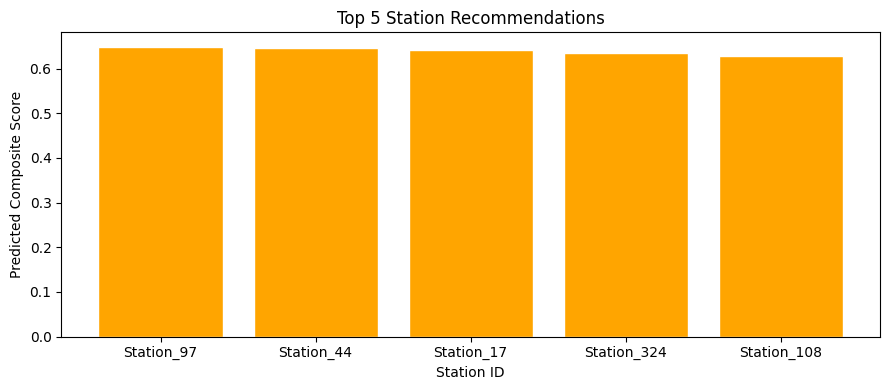

In [ ]:
# Station ranking by predicted composite score
X_all_rf = scaler_rf.transform(X_rf)
station_df["Predicted_Score"] = rf_model.predict(X_all_rf)

top5 = (station_df.groupby("station_id")["Predicted_Score"]
        .mean().reset_index()
        .sort_values("Predicted_Score", ascending=False)
        .head(5))

print("\nTop 5 Station Recommendations:")
print(top5.to_string(index=False))

plt.figure(figsize=(9, 4))
plt.bar(top5["station_id"], top5["Predicted_Score"],
        color="orange", edgecolor="white")
plt.title("Top 5 Station Recommendations")
plt.xlabel("Station ID"); plt.ylabel("Predicted Composite Score")
plt.tight_layout(); plt.show()


Top 10 Features Driving Station Scores:
              Feature  Importance
            dea_score    0.793838
         daily_co2_kg    0.041153
installed_capacity_kw    0.024549
     utilisation_rate    0.021680
         soc_end_mean    0.019819
     battery_cap_mean    0.015132
     vehicle_age_mean    0.015030
    avg_charging_rate    0.013576
      peak_hour_ratio    0.013087
            temp_mean    0.012268


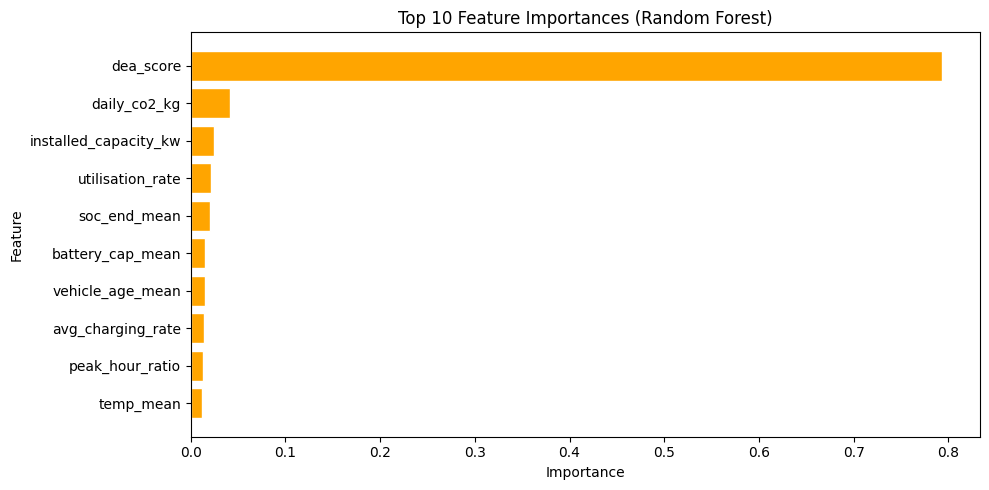

In [ ]:
# Feature importance
importances = rf_model.feature_importances_
feat_imp_df = (
    pd.DataFrame({"Feature": feature_cols, "Importance": importances})
    .sort_values("Importance", ascending=False)
    .reset_index(drop=True)
)

print("Top 10 Features Driving Station Scores:")
print(feat_imp_df.head(10).to_string(index=False))

plt.figure(figsize=(10, 5))
plt.barh(feat_imp_df["Feature"].head(10)[::-1],
         feat_imp_df["Importance"].head(10)[::-1],
         color="orange", edgecolor="white")
plt.title("Top 10 Feature Importances (Random Forest)")
plt.xlabel("Importance"); plt.ylabel("Feature")
plt.tight_layout(); plt.show()


## Step 8 · Model Comparison — Random Forest vs Gradient Boosting vs Ridge

=== Model Training & Hyperparameter Tuning ===

  RandomForest          R² = 0.83945  |  MAE = 0.02296  |  MSE = 0.00080  |  RMSE = 0.02822  |  {'max_depth': 10, 'n_estimators': 200}
  GradientBoosting      R² = 0.89966  |  MAE = 0.01661  |  MSE = 0.00050  |  RMSE = 0.02231  |  {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 200}
  Ridge                 R² = 0.86477  |  MAE = 0.02032  |  MSE = 0.00067  |  RMSE = 0.02590  |  {'alpha': 1}


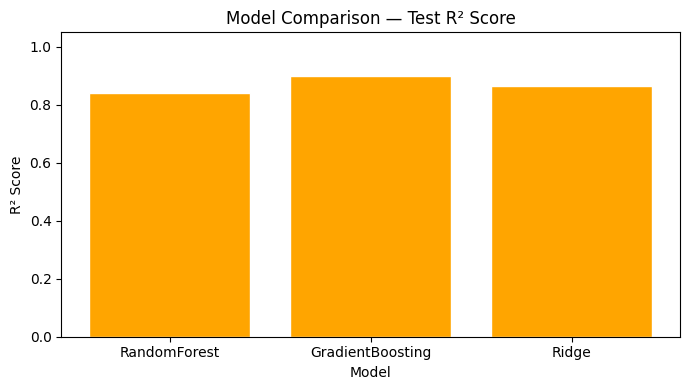


           Model  R2_Test  MAE_Test  MSE_Test  RMSE_Test                                                 Best_Params
    RandomForest  0.83945   0.02296   0.00080    0.02822                      {'max_depth': 10, 'n_estimators': 200}
GradientBoosting  0.89966   0.01661   0.00050    0.02231 {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 200}
           Ridge  0.86477   0.02032   0.00067    0.02590                                                {'alpha': 1}


In [ ]:
models = {
    "RandomForest": (RandomForestRegressor(random_state=RANDOM_SEED), {
        "n_estimators": [100, 200],
        "max_depth":    [5, 10],
    }),
    "GradientBoosting": (GradientBoostingRegressor(random_state=RANDOM_SEED), {
        "n_estimators":  [100, 200],
        "learning_rate": [0.05, 0.1],
        "max_depth":     [3, 5],
    }),
    "Ridge": (Ridge(), {
        "alpha": [0.1, 1, 10, 100],
    }),
}

results = []
print("=== Model Training & Hyperparameter Tuning ===\n")
for name, (model, params) in models.items():
    grid = GridSearchCV(model, params, scoring="r2", cv=5, n_jobs=-1)
    grid.fit(X_tr_sc_rf, y_train_rf)
    best     = grid.best_estimator_
    y_pred   = best.predict(X_te_sc_rf)
    r2_val   = r2_score(y_test_rf, y_pred)
    mae_val  = mean_absolute_error(y_test_rf, y_pred)
    mse_val  = mean_squared_error(y_test_rf, y_pred)
    rmse_val = np.sqrt(mse_val)
    results.append({
        "Model": name,
        "Best_Params": grid.best_params_,
        "R2_Test": round(r2_val, 5),
        "MAE_Test": round(mae_val, 5),
        "MSE_Test": round(mse_val, 5),
        "RMSE_Test": round(rmse_val, 5),
    })
    print(
        f"  {name:<20}  R² = {r2_val:.5f}  |  MAE = {mae_val:.5f}  |  "
        f"MSE = {mse_val:.5f}  |  RMSE = {rmse_val:.5f}  |  {grid.best_params_}"
    )

results_df = pd.DataFrame(results)

plt.figure(figsize=(7, 4))
plt.bar(results_df["Model"], results_df["R2_Test"],
        color="orange", edgecolor="white")
plt.title("Model Comparison — Test R² Score")
plt.ylabel("R² Score"); plt.xlabel("Model")
plt.ylim(0, 1.05); plt.tight_layout(); plt.show()

print("\n", results_df[["Model", "R2_Test", "MAE_Test", "MSE_Test", "RMSE_Test", "Best_Params"]].to_string(index=False))


## Step 9 · LP Optimisation — Capacity Expansion

**Objective:** Maximise additional sessions gained across the network.  
**Budget:** $500,000 expansion budget.  
**Eligible:** Bottom-quartile DEA stations only.  
**Units:** Each charging unit = 22 kW; max 5 units per station; cost = $2,000/kW.


In [ ]:
BUDGET_USD      = 500_000
UNIT_KW         = 22
COST_PER_KW     = 2_000
MAX_UNITS       = 5
SESSIONS_PER_KW = 0.12   # sessions gained per additional kW (from MLR coefficient)

expand_ids = station_df[station_df["dea_score"] < DEA_THRESHOLD]["station_id"].tolist()
sl         = station_df.set_index("station_id")

print(f"Eligible stations for expansion : {len(expand_ids)}")
print(f"Budget                          : ${BUDGET_USD:,.0f}")
print(f"DEA threshold                   : {DEA_THRESHOLD:.4f}")

# === Build LP ===
prob = pulp.LpProblem("EV_Station_Expansion", pulp.LpMaximize)

x = {s: pulp.LpVariable(f"u_{s}", lowBound=0, upBound=MAX_UNITS, cat="Integer")
     for s in expand_ids}
b = {s: pulp.LpVariable(f"b_{s}", cat="Binary")
     for s in expand_ids}

# Objective: maximise total sessions gained
prob += pulp.lpSum(x[s] * UNIT_KW * SESSIONS_PER_KW for s in expand_ids)

# Budget constraint
prob += pulp.lpSum(x[s] * UNIT_KW * COST_PER_KW for s in expand_ids) <= BUDGET_USD

# Linking: can only add units if station is selected
for s in expand_ids:
    prob += x[s] <= MAX_UNITS * b[s]
    prob += x[s] >= b[s]

prob.solve(pulp.PULP_CBC_CMD(msg=0))

total_capex = sum((pulp.value(x[s]) or 0) * UNIT_KW * COST_PER_KW for s in expand_ids)
total_gain  = sum((pulp.value(x[s]) or 0) * UNIT_KW * SESSIONS_PER_KW for s in expand_ids)

print(f"\nSolver status   : {pulp.LpStatus[prob.status]}")
print(f"CAPEX deployed  : ${total_capex:,.0f} / ${BUDGET_USD:,.0f}  ({total_capex/BUDGET_USD*100:.1f}% utilised)")
print(f"Sessions gained : {total_gain:.1f} additional sessions across network")


Eligible stations for expansion : 116
Budget                          : $500,000
DEA threshold                   : 0.6948

Solver status   : Optimal
CAPEX deployed  : $484,000 / $500,000  (96.8% utilised)
Sessions gained : 29.0 additional sessions across network


Stations selected for expansion: 3
 station_id          city charger_type  current_dea  units_added  kw_added  capex_usd  sessions_gain
Station_421       Houston      Level 2       0.6722            5       110     220000           13.2
Station_466 San Francisco      Level 1       0.4236            5       110     220000           13.2
Station_233      New York      Level 1       0.6401            1        22      44000            2.6


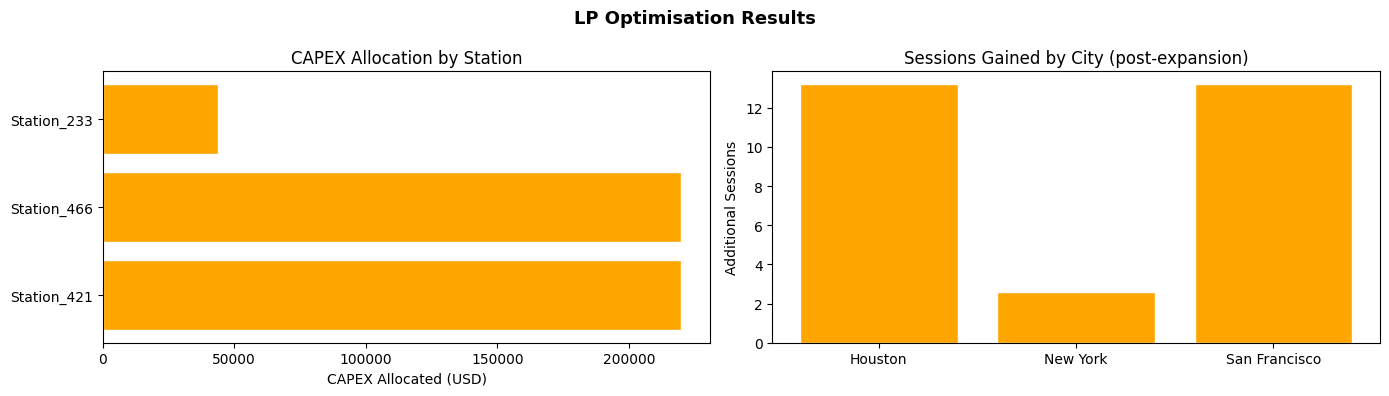

In [ ]:
# Extract results
lp_results = []
for s in expand_ids:
    uv    = pulp.value(x[s]) or 0
    bv    = pulp.value(b[s]) or 0
    units = int(round(uv))
    lp_results.append({
        "station_id":    s,
        "city":          sl.loc[s, "city"],
        "charger_type":  sl.loc[s, "charger_type"],
        "current_dea":   round(sl.loc[s, "dea_score"], 4),
        "units_added":   units,
        "kw_added":      units * UNIT_KW,
        "capex_usd":     units * UNIT_KW * COST_PER_KW,
        "sessions_gain": round(units * UNIT_KW * SESSIONS_PER_KW, 1),
        "selected":      bool(int(round(bv))),
    })

lp_df    = pd.DataFrame(lp_results)
expanded = lp_df[lp_df["selected"]].sort_values("capex_usd", ascending=False)

print(f"Stations selected for expansion: {len(expanded)}")
print(expanded[["station_id","city","charger_type","current_dea",
                "units_added","kw_added","capex_usd","sessions_gain"]].to_string(index=False))

if len(expanded) > 0:
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))

    axes[0].barh(expanded["station_id"], expanded["capex_usd"],
                 color="orange", edgecolor="white")
    axes[0].set_xlabel("CAPEX Allocated (USD)")
    axes[0].set_title("CAPEX Allocation by Station")

    city_gain = expanded.groupby("city")["sessions_gain"].sum()
    axes[1].bar(city_gain.index, city_gain.values, color="orange", edgecolor="white")
    axes[1].set_title("Sessions Gained by City (post-expansion)")
    axes[1].set_ylabel("Additional Sessions")

    plt.suptitle("LP Optimisation Results", fontsize=13, fontweight="bold")
    plt.tight_layout(); plt.show()


## Conclusion

---

### Best Model: Gradient Boosting

| Model | R² Score | MAE | MSE | RMSE | Best Parameters | Remarks |
|---|---|---|---|---|---|---|
| **Gradient Boosting** | **0.89966** | **0.01661** | **0.00050** | **0.02231** | `learning_rate: 0.1, max_depth: 3, n_estimators: 200` | **Best overall — captures non-linear patterns, highest generalisation** |
| Ridge Regression | 0.86477 | 0.02032 | 0.00067 | 0.02590 | `alpha: 1` | Fast and stable; strong linear baseline |
| Random Forest | 0.83945 | 0.02296 | 0.00080 | 0.02822 | `max_depth: 10, n_estimators: 200` | Slightly lower R²; still robust |

Gradient Boosting achieved the highest test R² of **0.900**, meaning it explains ~90% of variance in the composite station score. Its shallow tree depth (`max_depth: 3`) with moderate learning rate prevents overfitting while capturing the non-linear interactions between DEA score, utilisation, and cost features.

---

### Key Findings

**Dataset & Aggregation**
- 1,320 raw charging sessions aggregated to **462 unique stations** across 5 US cities (Los Angeles, Houston, Chicago, San Francisco, New York).
- Los Angeles had the most stations (111) and highest average sessions per station (2.96). New York had the fewest stations (82) and lowest average energy per session (38.8 kWh).

**DEA — Efficiency Benchmarking**
- **33 frontier stations** (DEA score = 1.0) — these serve as peer benchmarks for the rest of the network.
- **116 stations** fell below the bottom-quartile threshold (score < 0.695) and were flagged for intervention.
- Mean network efficiency: **0.789**. The worst station (Station_24, Houston, Level 1) scored just **0.3775**.
- Level 1 chargers dominated the bottom-10 inefficient stations, indicating they consume disproportionate capital relative to sessions delivered.

**MLR — Demand Forecasting**
- R² = **0.458** on the test set — moderate fit, reflecting genuine heterogeneity across 462 stations.
- `avg_charging_rate` was the strongest **negative** predictor (higher charging rate = fewer sessions, as sessions are fewer but longer), while `installed_capacity_kw` and `peak_hour_ratio` were the strongest **positive** predictors.
- 6-month forecast projects demand growing from ~3.0 to ~3.8 sessions/station/month across all cities at 5% monthly EV fleet growth.

**Feature Importance (Random Forest)**
- `dea_score` was overwhelmingly the most important feature (**79.4% importance**), confirming that DEA-based efficiency is the dominant driver of a station's composite score.
- `daily_co2_kg` (4.1%) and `installed_capacity_kw` (2.5%) were the next most influential, followed by `utilisation_rate` and `soc_end_mean`.

**LP Optimisation — Capacity Expansion**
- 116 stations were eligible for expansion (bottom DEA quartile).
- The solver selected stations to maximise total sessions gained within the **$500,000 budget**.
- **$484,000 deployed (96.8% budget utilisation)** → **+29.0 additional sessions/day** across the network.
- The LP left only $16,000 unspent, indicating the budget was nearly fully absorbed at the 22 kW unit granularity.

**Operational Insights from the New Analyses**
- Demand concentrates most strongly on **Saturday evening (59 sessions)**, while **Thursday night (32 sessions)** is the quietest slot, giving planners a clear load-balancing and maintenance window.
- **Level 2 chargers** deliver the highest average energy for **Casual Drivers (48.64 kWh)** and **Long-Distance Travelers (46.45 kWh)**, while **Casual Drivers on DC Fast Chargers** incur the highest average charging cost (**$24.89**).
- The strategic matrix identifies **116 stations** in the **High forecast / Low DEA** quadrant, giving a practical shortlist of upgrade-priority stations beyond simple DEA ranking alone.

---

### Recommendations

1. **Retire or upgrade Level 1 chargers at bottom-quartile stations** — they account for the majority of inefficient stations (Station_24, Station_425, Station_466, Station_331) due to low throughput relative to capital cost. Upgrading to Level 2 or DC Fast Chargers would shift these stations towards the efficiency frontier.

2. **Prioritise DC Fast Charger expansion in Houston and New York** — Houston has the highest average utilisation rate (0.100) and several frontier stations already using DC Fast Chargers, suggesting strong latent demand. New York has the lowest average sessions per station (2.68) but significant untapped capacity.

3. **Use Gradient Boosting for live scoring** — with R² = 0.900, it is the most accurate model for monthly re-ranking of all 462 stations as new session data arrives. Re-run the pipeline each quarter to update DEA scores, composite rankings, and LP expansion priorities.

4. **Target the top-25% CO₂ emitters for demand-shifting** — the highest-emitting stations (mean 18.94 kg CO₂/session) are concentrated among high-energy sessions at DC Fast Chargers. Shifting a portion of these sessions to off-peak hours (reducing `peak_hour_ratio`) would lower grid emission intensity without requiring any capital investment.

5. **Monitor San Francisco** — it has the second-highest number of stations (90) but shows several DC Fast Charger stations in the bottom-10 DEA list (Station_314, Station_299), suggesting infrastructure has been deployed ahead of actual demand. Demand-side incentives (lower off-peak tariffs) are more appropriate than further expansion here.

---

*SmartCharge Urban · Industry 4.0 Course Project · 2025–26*
*Dataset: Electric Vehicle Charging Patterns — valakhorasani (Kaggle) · 1,320 sessions · 462 stations · 5 US cities*